# Primary Notebook SDEP

In [1]:
import os
import pandas as pd
from glob import glob
import numpy as np
import matplotlib.pyplot as plt
from math import sqrt
from scipy.ndimage import gaussian_filter
from scipy.signal import savgol_filter
from scipy.ndimage import rotate
import json
import cv2
from align_images_functions import *
from other_necessary_functions import *
from starting_angle_functions import *
from plotting_paths_functions import * 

## Stim Duration Exploration Project (SDEP)

### plot all trials in a folder speed vs time (stim superposed)

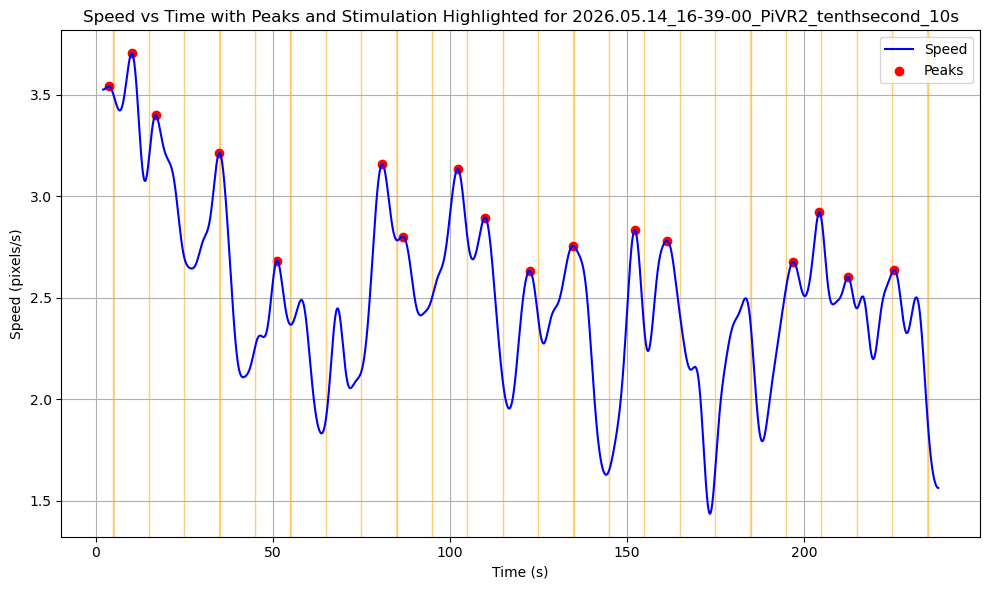

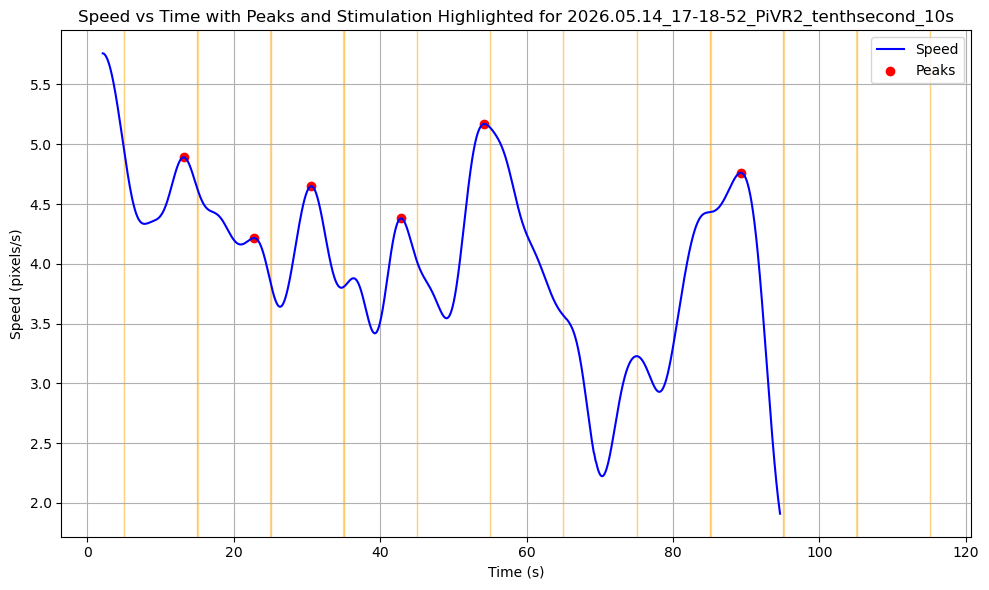

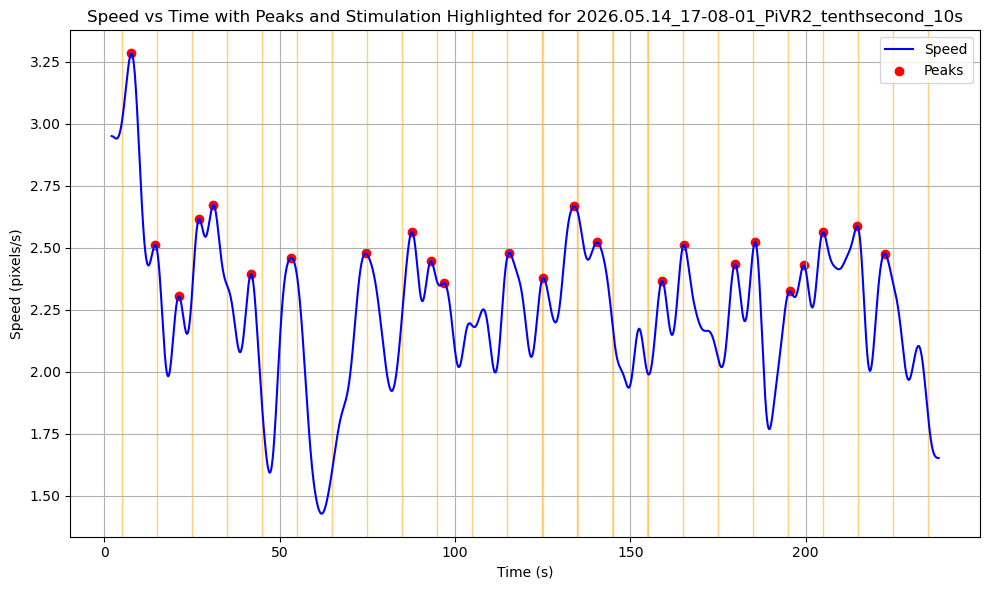

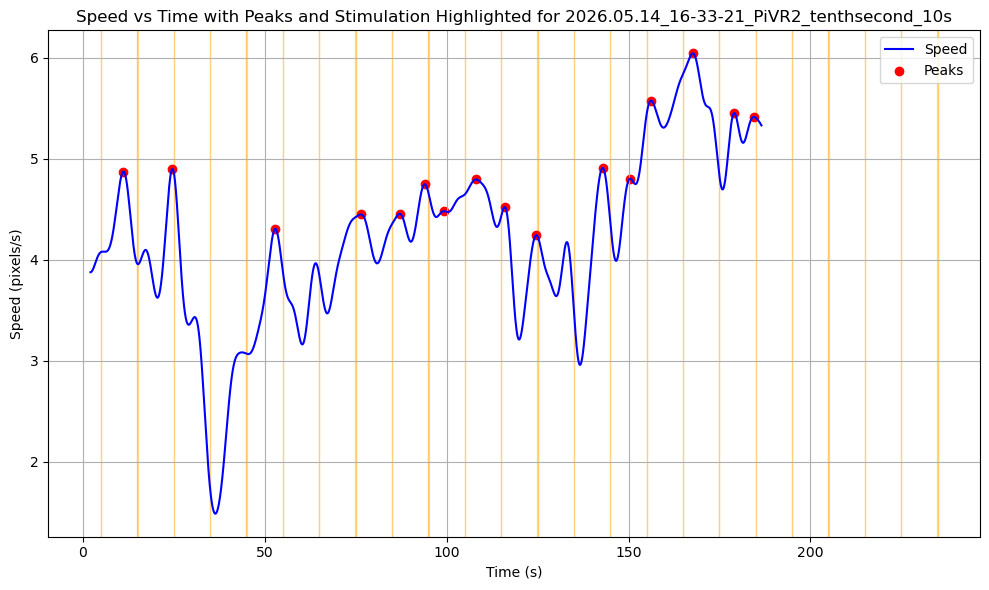

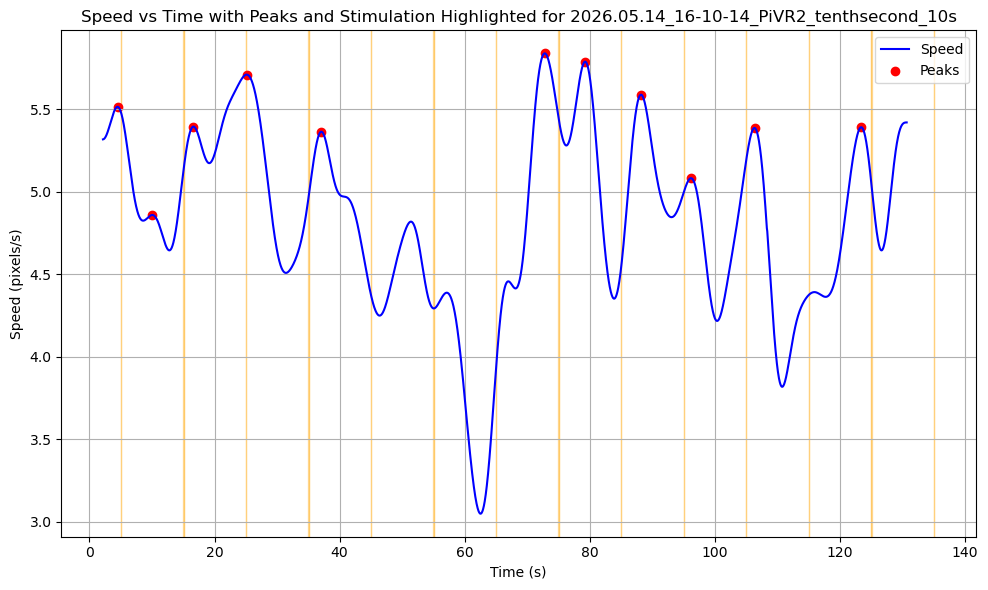

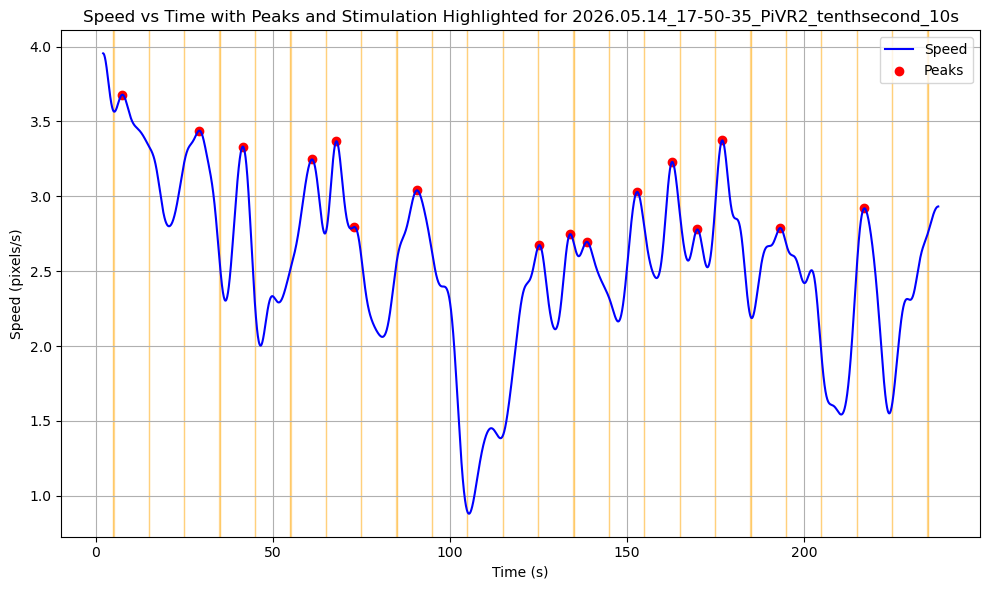

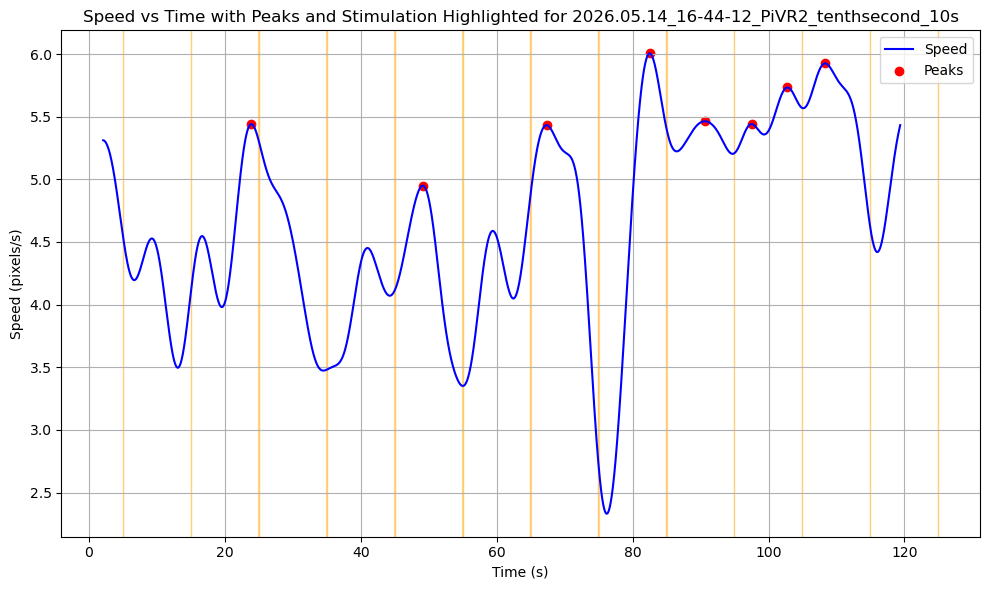

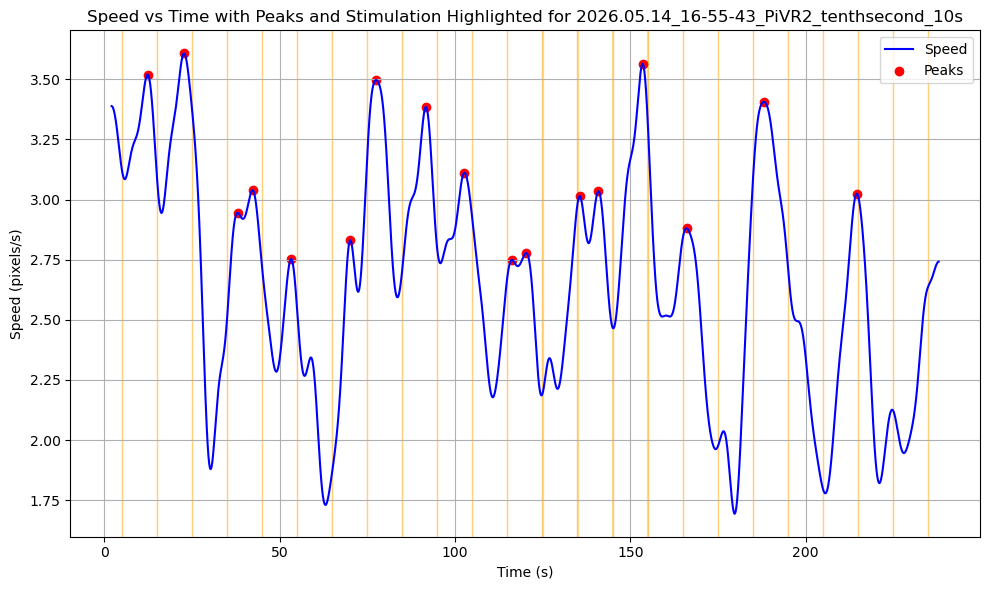

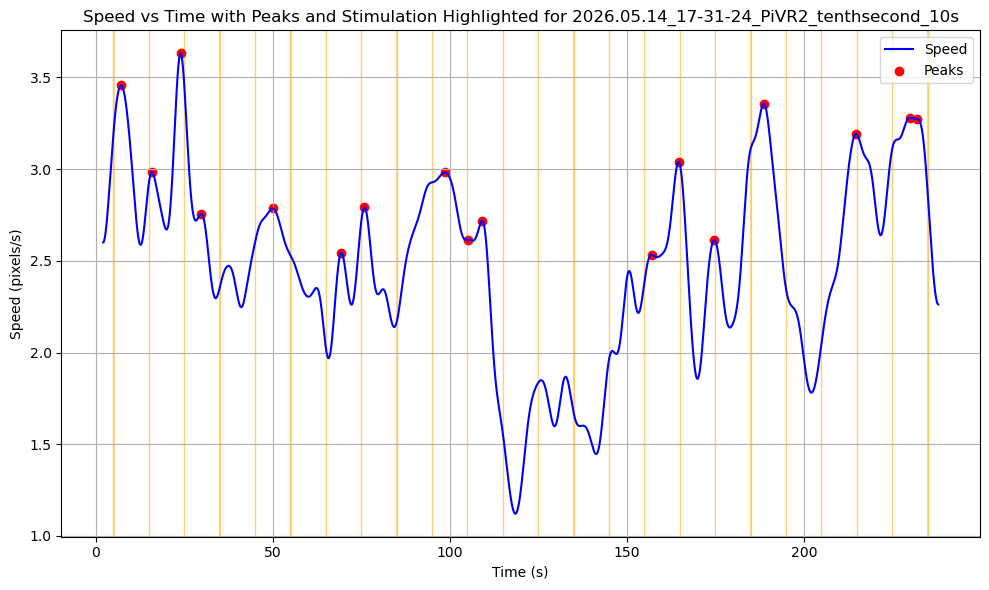

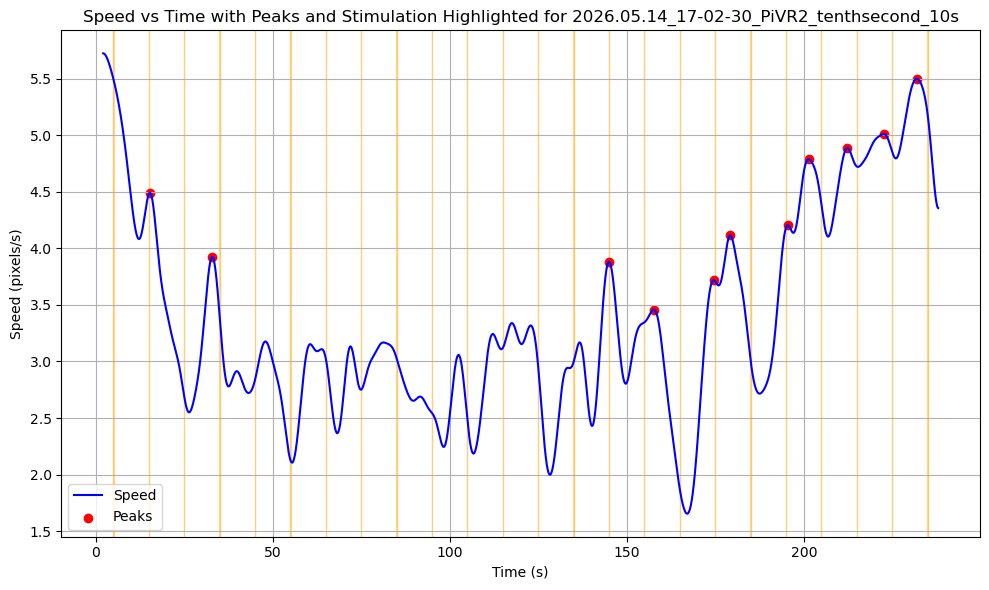

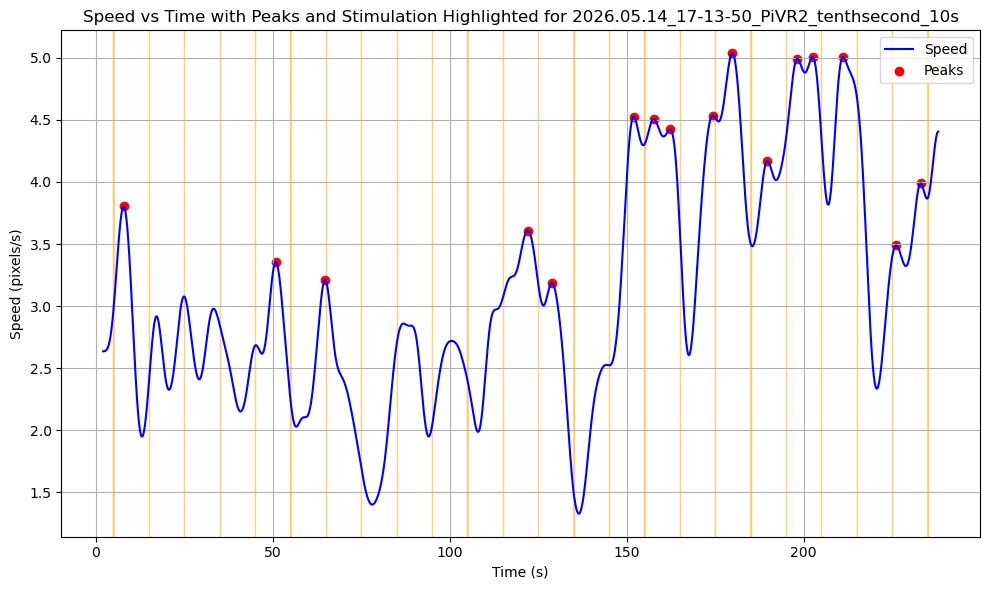

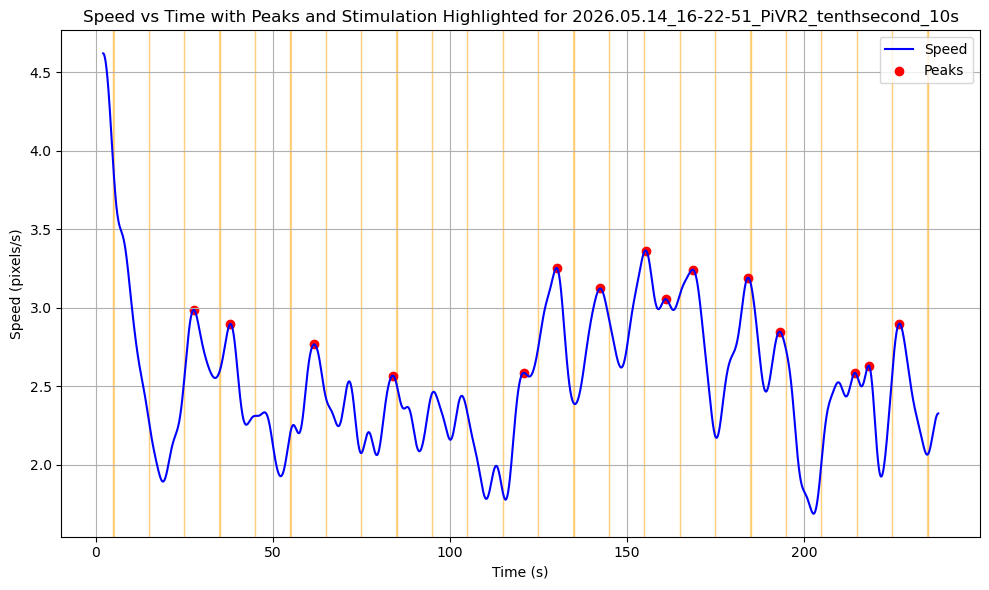

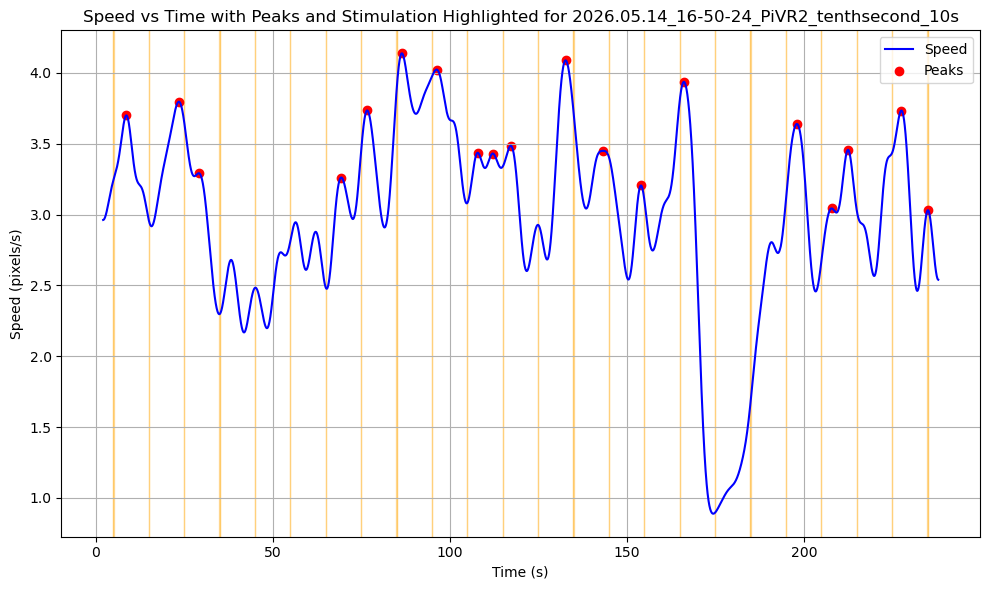

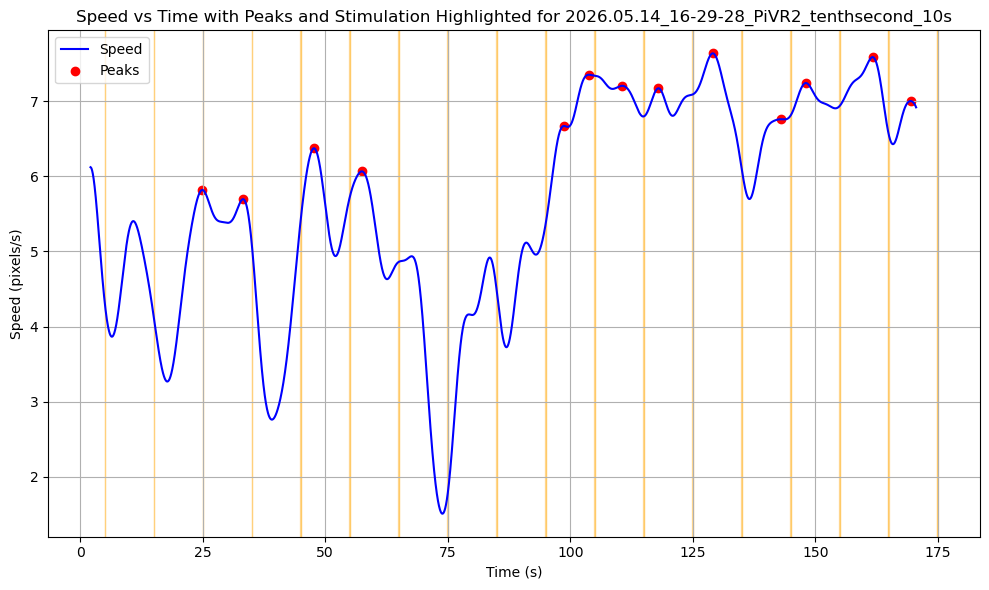

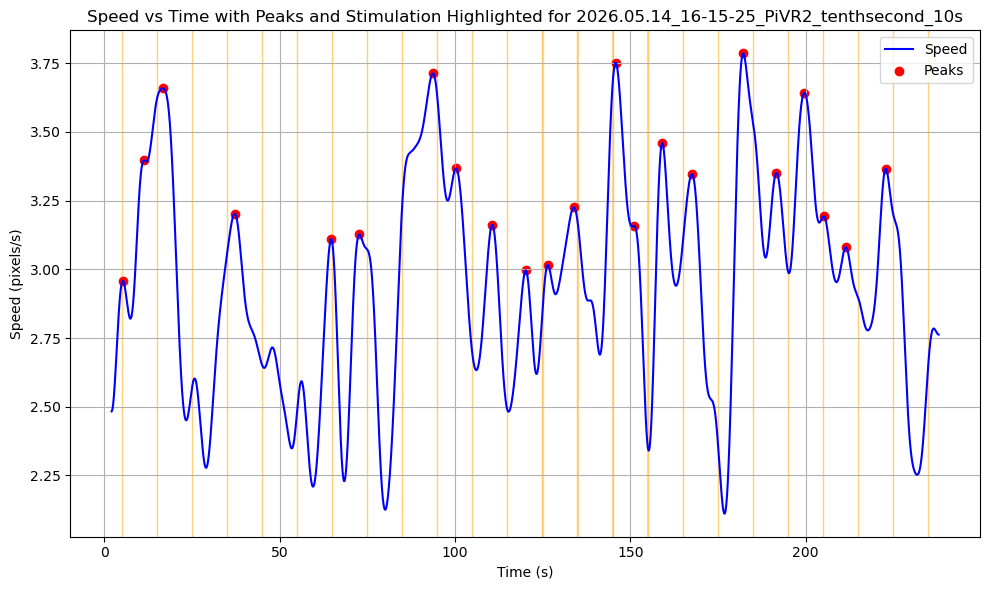

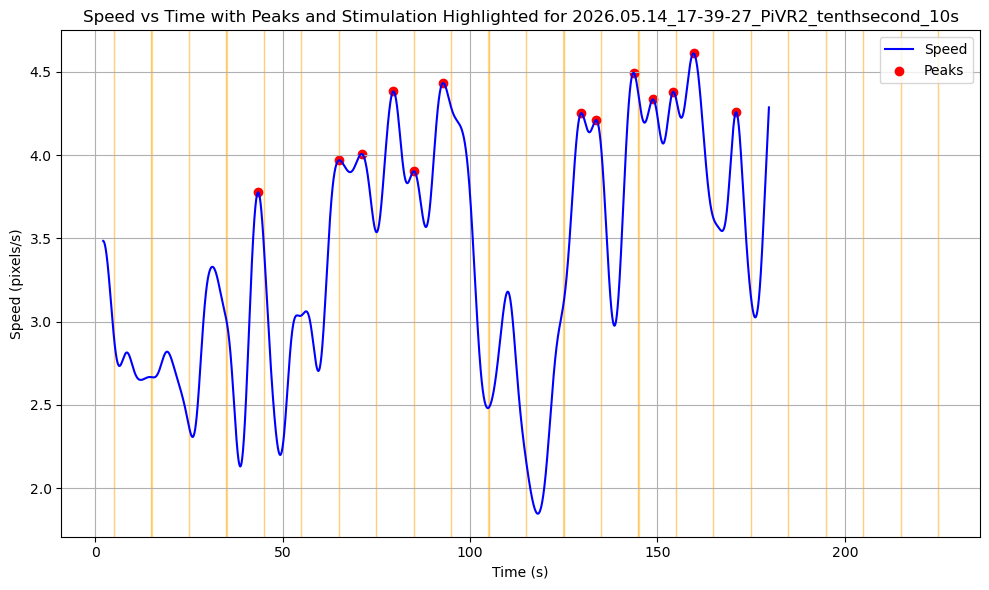

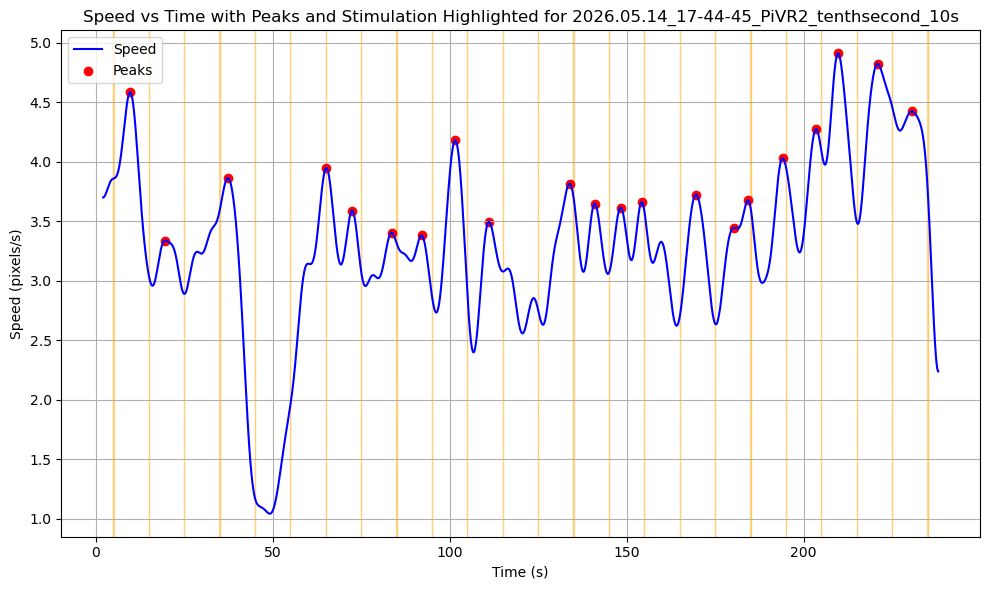

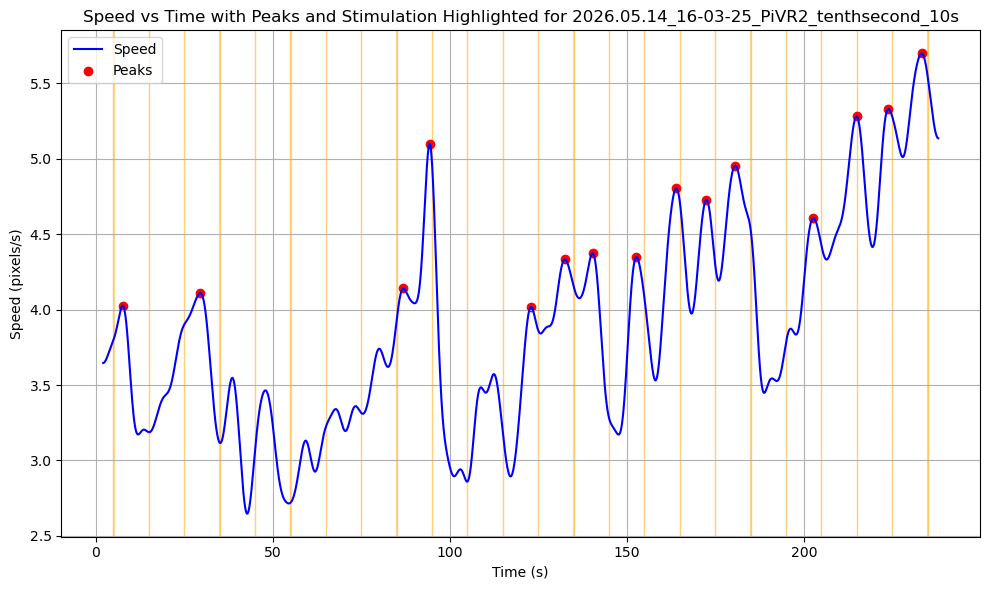

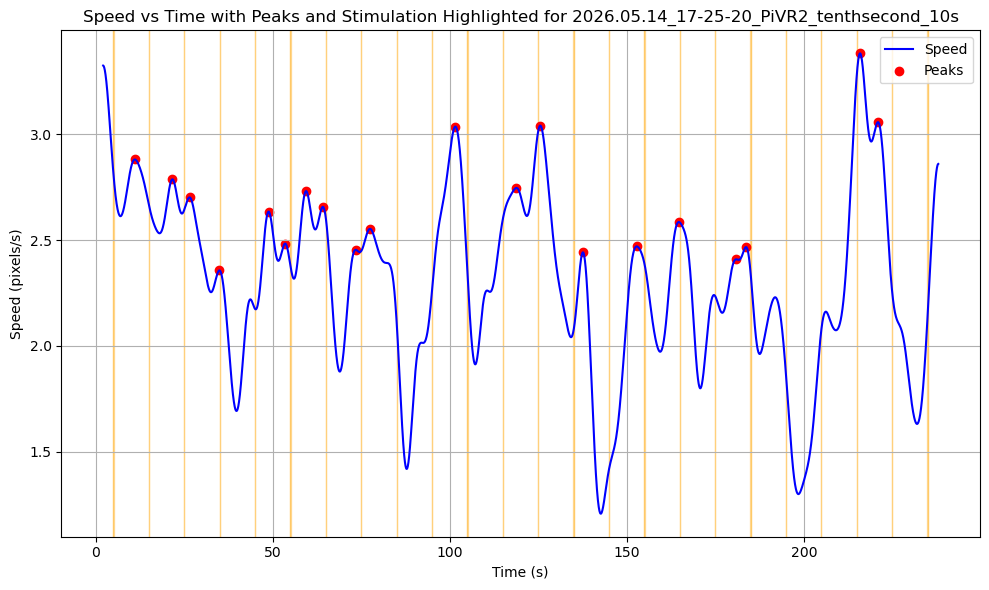

In [4]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter, find_peaks
from scipy.ndimage import gaussian_filter

def plot_speed_with_peaks_and_stimulation_highlight(base_folder, stimulation_column="stimulation", stimvalue = 80.0, smoothing_factor = 100):
    """
    Plot the speed data for all experiments in a folder, highlight the peaks, and highlight sections where stimulation is "turned on."

    Parameters:
        base_folder (str): Path to the folder containing subfolders with GUI-corrected files.
        stimulation_column (str): The column name representing stimulation (e.g., "stimulation" or "Stim Ch1").

    Returns:
        None
    """
    for folder in os.listdir(base_folder):
        folder_path = os.path.join(base_folder, folder)
        if not os.path.isdir(folder_path):
            continue

        # Find the GUI-corrected file in the folder
        gui_corrected_files = [
            f for f in os.listdir(folder_path)
            if f.endswith("GUIcorrected.csv") and not f.startswith("aligned_")
        ]
        if not gui_corrected_files:
            print(f"No GUI-corrected file found in {folder_path}. Skipping.")
            continue

        gui_corrected_file = gui_corrected_files[0]
        gui_corrected_path = os.path.join(folder_path, gui_corrected_file)

        # Read the GUI-corrected file
        data = pd.read_csv(gui_corrected_path)

        # Ensure required columns exist
        required_columns = ['X-Midpoint', 'Y-Midpoint', 'Time', stimulation_column]
        if not all(col in data.columns for col in required_columns):
            print(f"Required columns not found in {gui_corrected_file}. Skipping.")
            continue

        # Remove the first and last 60 frames
        if len(data) > 120:
            data = data.iloc[60:-60]
        else:
            print(f"Not enough frames in {gui_corrected_file}. Skipping.")
            continue

        # Smooth the data using Savitzky-Golay filter
        window_length = 31  # Must be odd and less than the length of the data
        polyorder = 3       # Polynomial order for the filter
        data['X-Midpoint'] = savgol_filter(data['X-Midpoint'], window_length, polyorder)
        data['Y-Midpoint'] = savgol_filter(data['Y-Midpoint'], window_length, polyorder)

        # Calculate the speed
        x_midpoint = data['X-Midpoint'].values
        y_midpoint = data['Y-Midpoint'].values
        time = data['Time'].values
        stimulation = data[stimulation_column].values

        # Calculate the differences in positions and time
        dx = np.diff(x_midpoint)
        dy = np.diff(y_midpoint)
        dt = np.diff(time)

        # Avoid division by zero
        dt[dt == 0] = np.nan

        # Calculate speed (pixels per unit time)
        speed = np.sqrt(dx**2 + dy**2) / dt
        speed = np.clip(speed, 0, np.nanpercentile(speed, 95))  # Remove extreme outliers
        speed_smoothed = gaussian_filter(speed, sigma = smoothing_factor)

        # Detect peaks in the speed data
        peak_indices, _ = find_peaks(speed_smoothed, height=np.nanmean(speed_smoothed))  # Peaks above the mean speed
        speed_at_peaks = speed_smoothed[peak_indices]

        # Plot the speed data with peaks highlighted
        plt.figure(figsize=(10, 6))
        plt.plot(time[1:], speed_smoothed, label="Speed", color="blue")

        # Highlight sections where stimulation is "turned on" (value = 8000.0)
        stimulation_on = stimulation == stimvalue 

        # Ensure stimulation_on and speed_smoothed are the same length
        min_length = min(len(stimulation_on), len(speed_smoothed))
        stimulation_on = stimulation_on[:min_length]
        speed_smoothed = speed_smoothed[:min_length]
        time = time[:min_length]

        for i in range(len(stimulation_on) - 1):
            if stimulation_on[i] and stimulation_on[i + 1]:  # Continuous "on" section
                plt.axvspan(time[i], time[i + 1], color="orange", alpha=0.3, label="Stimulation On" if i == 0 else "")

        plt.scatter(time[1:][peak_indices], speed_at_peaks, color="red", label="Peaks")
        plt.xlabel("Time (s)")
        plt.ylabel("Speed (pixels/s)")
        plt.title(f"Speed vs Time with Peaks and Stimulation Highlighted for {folder}")
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.show()

# Example usage
base_folder = '/Users/eneko/Desktop/Louis Lab/data collection/260514/tenthsecond_10s'  # Replace with your folder path
plot_speed_with_peaks_and_stimulation_highlight(base_folder, stimulation_column="Stim Ch1", stimvalue = 80.0, smoothing_factor = 50)

### combined experiments (averaged)

/var/folders/0h/9yk7tm0s0d97xz7p8k6qxzt00000gn/T/ipykernel_79750/2386264912.py:101: RuntimeWarning: Mean of empty slice
  average_speed = np.nanmean(padded_speeds, axis=0)


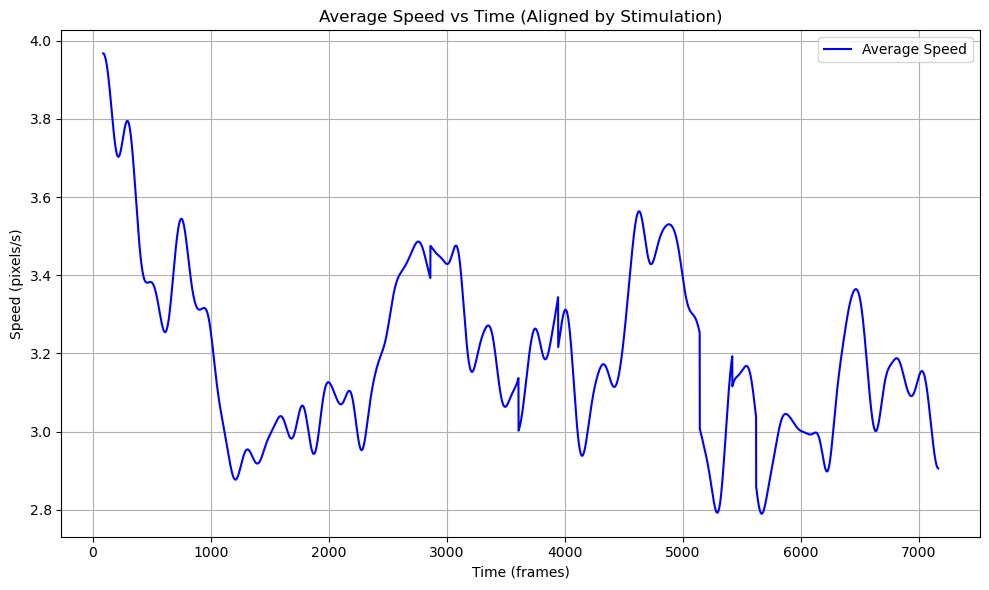

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter, find_peaks
from scipy.ndimage import gaussian_filter

def plot_average_speed(base_folder, stimulation_column="stimulation", stimvalue=80.0, smoothing_factor=100):
    """
    Aligns all experiments by the first stimulation frame, superposes the speed data, 
    and plots the average speed across all trials.

    Parameters:
        base_folder (str): Path to the folder containing subfolders with GUI-corrected files.
        stimulation_column (str): The column name representing stimulation (e.g., "stimulation" or "Stim Ch1").
        stimvalue (float): The value in the stimulation column that indicates stimulation is "on".
        smoothing_factor (int): The smoothing factor for the Gaussian filter.

    Returns:
        None
    """
    all_speeds = []
    max_length = 0

    for folder in os.listdir(base_folder):
        folder_path = os.path.join(base_folder, folder)
        if not os.path.isdir(folder_path):
            continue

        # Find the GUI-corrected file in the folder
        gui_corrected_files = [
            f for f in os.listdir(folder_path)
            if f.endswith("GUIcorrected.csv") and not f.startswith("aligned_")
        ]
        if not gui_corrected_files:
            print(f"No GUI-corrected file found in {folder_path}. Skipping.")
            continue

        gui_corrected_file = gui_corrected_files[0]
        gui_corrected_path = os.path.join(folder_path, gui_corrected_file)

        # Read the GUI-corrected file
        data = pd.read_csv(gui_corrected_path)

        # Ensure required columns exist
        required_columns = ['X-Midpoint', 'Y-Midpoint', 'Time', stimulation_column]
        if not all(col in data.columns for col in required_columns):
            print(f"Required columns not found in {gui_corrected_file}. Skipping.")
            continue

        # Remove the first and last 60 frames
        if len(data) > 120:
            data = data.iloc[60:-60]
        else:
            print(f"Not enough frames in {gui_corrected_file}. Skipping.")
            continue

        # Smooth the data using Savitzky-Golay filter
        window_length = 31  # Must be odd and less than the length of the data
        polyorder = 3       # Polynomial order for the filter
        data['X-Midpoint'] = savgol_filter(data['X-Midpoint'], window_length, polyorder)
        data['Y-Midpoint'] = savgol_filter(data['Y-Midpoint'], window_length, polyorder)

        # Calculate the speed
        x_midpoint = data['X-Midpoint'].values
        y_midpoint = data['Y-Midpoint'].values
        time = data['Time'].values
        stimulation = data[stimulation_column].values

        # Calculate the differences in positions and time
        dx = np.diff(x_midpoint)
        dy = np.diff(y_midpoint)
        dt = np.diff(time)

        # Avoid division by zero
        dt[dt == 0] = np.nan

        # Calculate speed (pixels per unit time)
        speed = np.sqrt(dx**2 + dy**2) / dt
        speed = np.clip(speed, 0, np.nanpercentile(speed, 95))  # Remove extreme outliers
        speed_smoothed = gaussian_filter(speed, sigma=smoothing_factor)

        # Align by the first stimulation frame
        stim_indices = np.where(stimulation == stimvalue)[0]
        if len(stim_indices) == 0:
            print(f"No stimulation found in {gui_corrected_file}. Skipping.")
            continue
        first_stim_index = stim_indices[0]

        # Shift the speed data to align with the first stimulation frame
        aligned_speed = np.zeros(len(speed_smoothed) + first_stim_index) * np.nan
        aligned_speed[first_stim_index:first_stim_index + len(speed_smoothed)] = speed_smoothed

        all_speeds.append(aligned_speed)
        max_length = max(max_length, len(aligned_speed))

    # Pad all speeds to the same length
    padded_speeds = np.array([np.pad(s, (0, max_length - len(s)), constant_values=np.nan) for s in all_speeds])

    # Calculate the average speed across all trials
    average_speed = np.nanmean(padded_speeds, axis=0)

    # Plot the average speed
    plt.figure(figsize=(10, 6))
    time_vector = np.arange(len(average_speed))  # Assuming uniform time steps
    plt.plot(time_vector, average_speed, label="Average Speed", color="blue")
 
    plt.xlabel("Time (frames)")
    plt.ylabel("Speed (pixels/s)")
    plt.title("Average Speed vs Time (Aligned by Stimulation)")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# Example usage
base_folder = '/Users/eneko/Desktop/Louis Lab/data collection/260514/tenthsecond_10s'  # Replace with your folder path
plot_average_speed(base_folder, stimulation_column="Stim Ch1", stimvalue=80.0, smoothing_factor=50)


In [10]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from scipy.ndimage import gaussian_filter

def plot_average_speed_with_stimulation(base_folder, stimulation_column="stimulation", stimvalue=80.0, smoothing_factor=100):
    """
    Aligns all experiments by the first stimulation frame, superposes the speed data, 
    and plots the average speed across all trials with stimulation periods highlighted.

    Parameters:
        base_folder (str): Path to the folder containing subfolders with GUI-corrected files.
        stimulation_column (str): The column name representing stimulation (e.g., "stimulation" or "Stim Ch1").
        stimvalue (float): The value in the stimulation column that indicates stimulation is "on".
        smoothing_factor (int): The smoothing factor for the Gaussian filter.

    Returns:
        None
    """
    all_speeds = []
    max_length = 0
    stim_on_periods = []

    for folder in os.listdir(base_folder):
        folder_path = os.path.join(base_folder, folder)
        if not os.path.isdir(folder_path):
            continue

        # Find the GUI-corrected file in the folder
        gui_corrected_files = [
            f for f in os.listdir(folder_path)
            if f.endswith("GUIcorrected.csv") and not f.startswith("aligned_")
        ]
        if not gui_corrected_files:
            print(f"No GUI-corrected file found in {folder_path}. Skipping.")
            continue

        gui_corrected_file = gui_corrected_files[0]
        gui_corrected_path = os.path.join(folder_path, gui_corrected_file)

        # Read the GUI-corrected file
        data = pd.read_csv(gui_corrected_path)

        # Ensure required columns exist
        required_columns = ['X-Midpoint', 'Y-Midpoint', 'Time', stimulation_column]
        if not all(col in data.columns for col in required_columns):
            print(f"Required columns not found in {gui_corrected_file}. Skipping.")
            continue

        # Remove the first and last 60 frames
        if len(data) > 120:
            data = data.iloc[60:-60]
        else:
            print(f"Not enough frames in {gui_corrected_file}. Skipping.")
            continue

        # Smooth the data using Savitzky-Golay filter
        window_length = 31  # Must be odd and less than the length of the data
        polyorder = 3       # Polynomial order for the filter
        data['X-Midpoint'] = savgol_filter(data['X-Midpoint'], window_length, polyorder)
        data['Y-Midpoint'] = savgol_filter(data['Y-Midpoint'], window_length, polyorder)

        # Calculate the speed
        x_midpoint = data['X-Midpoint'].values
        y_midpoint = data['Y-Midpoint'].values
        time = data['Time'].values
        stimulation = data[stimulation_column].values

        # Calculate the differences in positions and time
        dx = np.diff(x_midpoint)
        dy = np.diff(y_midpoint)
        dt = np.diff(time)

        # Avoid division by zero
        dt[dt == 0] = np.nan

        # Calculate speed (pixels per unit time)
        speed = np.sqrt(dx**2 + dy**2) / dt
        speed = np.clip(speed, 0, np.nanpercentile(speed, 95))  # Remove extreme outliers
        speed_smoothed = gaussian_filter(speed, sigma=smoothing_factor)

        # Align by the first stimulation frame
        stim_indices = np.where(stimulation == stimvalue)[0]
        if len(stim_indices) == 0:
            print(f"No stimulation found in {gui_corrected_file}. Skipping.")
            continue
        first_stim_index = stim_indices[0]

        # Shift the speed data to align with the first stimulation frame
        aligned_speed = np.zeros(len(speed_smoothed) + first_stim_index) * np.nan
        aligned_speed[first_stim_index:first_stim_index + len(speed_smoothed)] = speed_smoothed

        # Record stimulation periods relative to the alignment
        stim_on = np.where(stimulation == stimvalue)[0] - first_stim_index
        stim_on_periods.append(stim_on)

        all_speeds.append(aligned_speed)
        max_length = max(max_length, len(aligned_speed))

    # Pad all speeds to the same length
    padded_speeds = np.array([np.pad(s, (0, max_length - len(s)), constant_values=np.nan) for s in all_speeds])

    # Calculate the average speed across all trials
    average_speed = np.nanmean(padded_speeds, axis=0)

    # Plot the average speed
    plt.figure(figsize=(10, 6))
    time_vector = np.arange(len(average_speed))  # Assuming uniform time steps
    plt.plot(time_vector, average_speed, label="Average Speed", color="blue")

    # Highlight stimulation periods
    for stim_on in stim_on_periods:
        for stim_frame in stim_on:
            if stim_frame >= 0 and stim_frame < len(time_vector) - 1:
                plt.axvspan(stim_frame, stim_frame + 1, color="orange", alpha=0.3)

    plt.xlabel("Time (frames)")
    plt.ylabel("Speed (pixels/s)")
    plt.title(f"Average Speed vs Time (Aligned by Stimulation) for {os.path.basename(base_folder)}")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


#### 1/10 second pulses

/var/folders/0h/9yk7tm0s0d97xz7p8k6qxzt00000gn/T/ipykernel_79750/2752920312.py:106: RuntimeWarning: Mean of empty slice
  average_speed = np.nanmean(padded_speeds, axis=0)


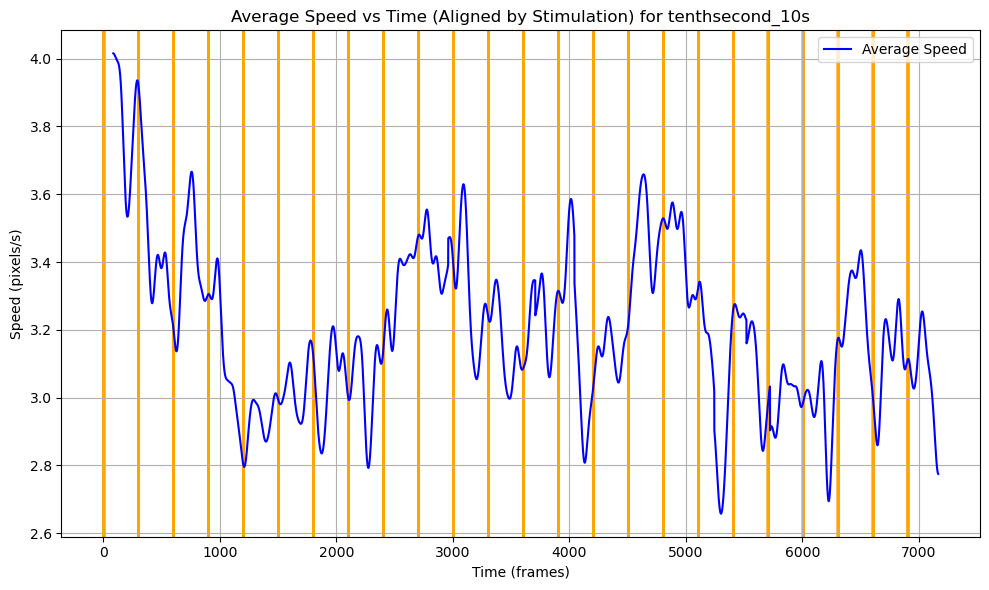

In [14]:
base_folder = '/Users/eneko/Desktop/Louis Lab/data collection/260514/tenthsecond_10s'  # Replace with your folder path
plot_average_speed_with_stimulation(base_folder, stimulation_column="Stim Ch1", stimvalue=80.0, smoothing_factor=25)

#### 1/2 second pulses

/var/folders/0h/9yk7tm0s0d97xz7p8k6qxzt00000gn/T/ipykernel_79750/2752920312.py:106: RuntimeWarning: Mean of empty slice
  average_speed = np.nanmean(padded_speeds, axis=0)


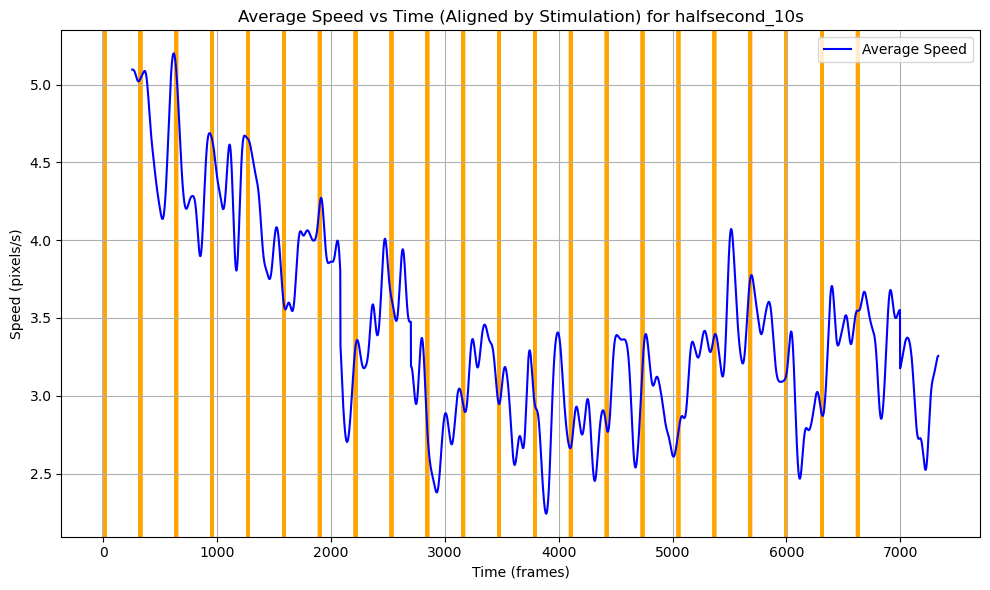

In [15]:
base_folder = '/Users/eneko/Desktop/Louis Lab/data collection/260514/halfsecond_10s'  # Replace with your folder path
plot_average_speed_with_stimulation(base_folder, stimulation_column="Stim Ch1", stimvalue=80.0, smoothing_factor=25)


### overlaying each iteration after the stimulation 

In [19]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from scipy.ndimage import gaussian_filter

def plot_average_intervals_with_stimulation(base_folder, stimulation_column="stimulation", stimvalue=80.0, smoothing_factor=100):
    """
    Splits each experiment into intervals between stimulations, aligns them, superposes the intervals, 
    and plots the average speed across all intervals with stimulation periods highlighted.

    Parameters:
        base_folder (str): Path to the folder containing subfolders with GUI-corrected files.
        stimulation_column (str): The column name representing stimulation (e.g., "stimulation" or "Stim Ch1").
        stimvalue (float): The value in the stimulation column that indicates stimulation is "on".
        smoothing_factor (int): The smoothing factor for the Gaussian filter.

    Returns:
        None
    """
    all_intervals = []
    max_interval_length = 0

    for folder in os.listdir(base_folder):
        folder_path = os.path.join(base_folder, folder)
        if not os.path.isdir(folder_path):
            continue

        # Find the GUI-corrected file in the folder
        gui_corrected_files = [
            f for f in os.listdir(folder_path)
            if f.endswith("GUIcorrected.csv") and not f.startswith("aligned_")
        ]
        if not gui_corrected_files:
            print(f"No GUI-corrected file found in {folder_path}. Skipping.")
            continue

        gui_corrected_file = gui_corrected_files[0]
        gui_corrected_path = os.path.join(folder_path, gui_corrected_file)

        # Read the GUI-corrected file
        data = pd.read_csv(gui_corrected_path)

        # Ensure required columns exist
        required_columns = ['X-Midpoint', 'Y-Midpoint', 'Time', stimulation_column]
        if not all(col in data.columns for col in required_columns):
            print(f"Required columns not found in {gui_corrected_file}. Skipping.")
            continue

        # Remove the first and last 60 frames
        if len(data) > 120:
            data = data.iloc[60:-60]
        else:
            print(f"Not enough frames in {gui_corrected_file}. Skipping.")
            continue

        # Smooth the data using Savitzky-Golay filter
        window_length = 31  # Must be odd and less than the length of the data
        polyorder = 3       # Polynomial order for the filter
        data['X-Midpoint'] = savgol_filter(data['X-Midpoint'], window_length, polyorder)
        data['Y-Midpoint'] = savgol_filter(data['Y-Midpoint'], window_length, polyorder)

        # Calculate the speed
        x_midpoint = data['X-Midpoint'].values
        y_midpoint = data['Y-Midpoint'].values
        time = data['Time'].values
        stimulation = data[stimulation_column].values

        # Calculate the differences in positions and time
        dx = np.diff(x_midpoint)
        dy = np.diff(y_midpoint)
        dt = np.diff(time)

        # Avoid division by zero
        dt[dt == 0] = np.nan

        # Calculate speed (pixels per unit time)
        speed = np.sqrt(dx**2 + dy**2) / dt
        speed = np.clip(speed, 0, np.nanpercentile(speed, 95))  # Remove extreme outliers
        speed_smoothed = gaussian_filter(speed, sigma=smoothing_factor)

        # Find stimulation indices
        stim_indices = np.where(stimulation == stimvalue)[0]
        if len(stim_indices) < 2:
            print(f"Not enough stimulations found in {gui_corrected_file}. Skipping.")
            continue

        # Split into intervals between stimulations
        for i in range(len(stim_indices) - 1):
            start = stim_indices[i]
            end = stim_indices[i + 1]
            interval_speed = speed_smoothed[start:end]
            all_intervals.append(interval_speed)
            max_interval_length = max(max_interval_length, len(interval_speed))

    # Pad all intervals to the same length
    padded_intervals = np.array([np.pad(interval, (0, max_interval_length - len(interval)), constant_values=np.nan) for interval in all_intervals])

    # Calculate the average speed across all intervals
    average_interval_speed = np.nanmean(padded_intervals, axis=0)

    # Plot the average interval speed
    plt.figure(figsize=(10, 6))
    time_vector = np.arange(len(average_interval_speed))  # Assuming uniform time steps
    plt.plot(time_vector, average_interval_speed, label="Average Interval Speed", color="blue")

    # Highlight stimulation periods
    stim_duration = stim_indices[1] - stim_indices[0]  # Assuming uniform stim duration
    plt.axvspan(0, stim_duration, color="orange", alpha=0.3, label="Stimulation")

    plt.xlabel("Time (frames)")
    plt.ylabel("Speed (pixels/s)")
    plt.title(f"Average Speed Across Intervals (Aligned by Stimulation) for {os.path.basename(base_folder)}")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

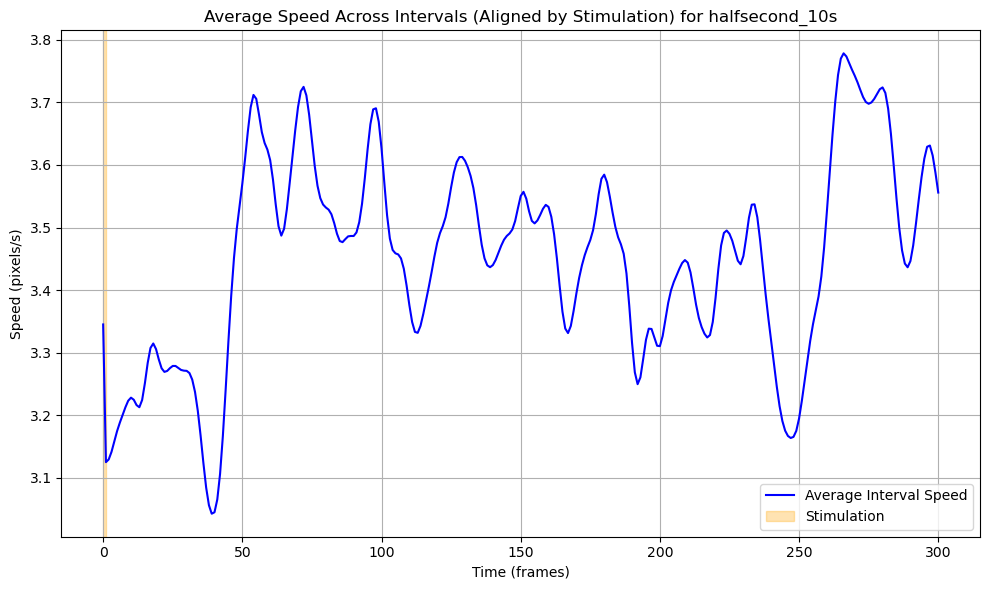

In [27]:
base_folder = '/Users/eneko/Desktop/Louis Lab/data collection/260514/halfsecond_10s'  # Replace with your folder path
plot_average_intervals_with_stimulation(base_folder, stimulation_column="Stim Ch1", stimvalue=80.0, smoothing_factor=2)


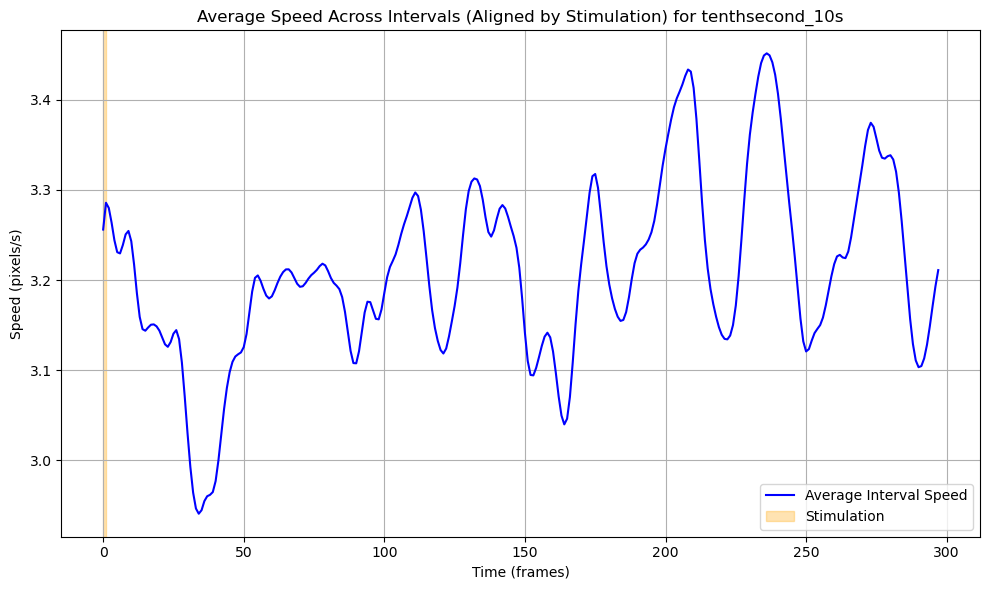

In [28]:
base_folder = '/Users/eneko/Desktop/Louis Lab/data collection/260514/tenthsecond_10s'  # Replace with your folder path
plot_average_intervals_with_stimulation(base_folder, stimulation_column="Stim Ch1", stimvalue=80.0, smoothing_factor=2)


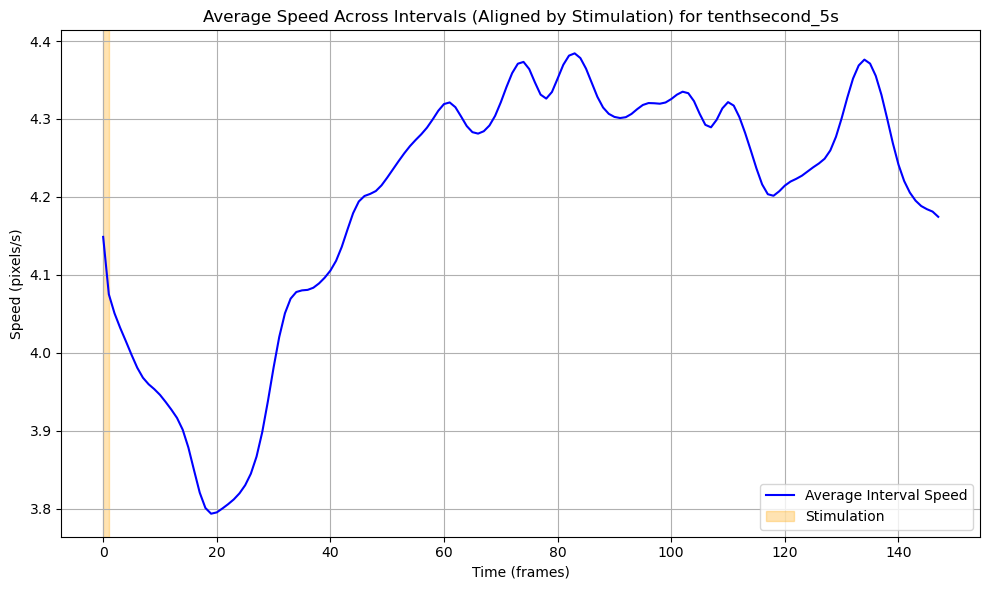

In [29]:
base_folder = '/Users/eneko/Desktop/Louis Lab/data collection/260514/tenthsecond_5s'  # Replace with your folder path
plot_average_intervals_with_stimulation(base_folder, stimulation_column="Stim Ch1", stimvalue=80.0, smoothing_factor=2)


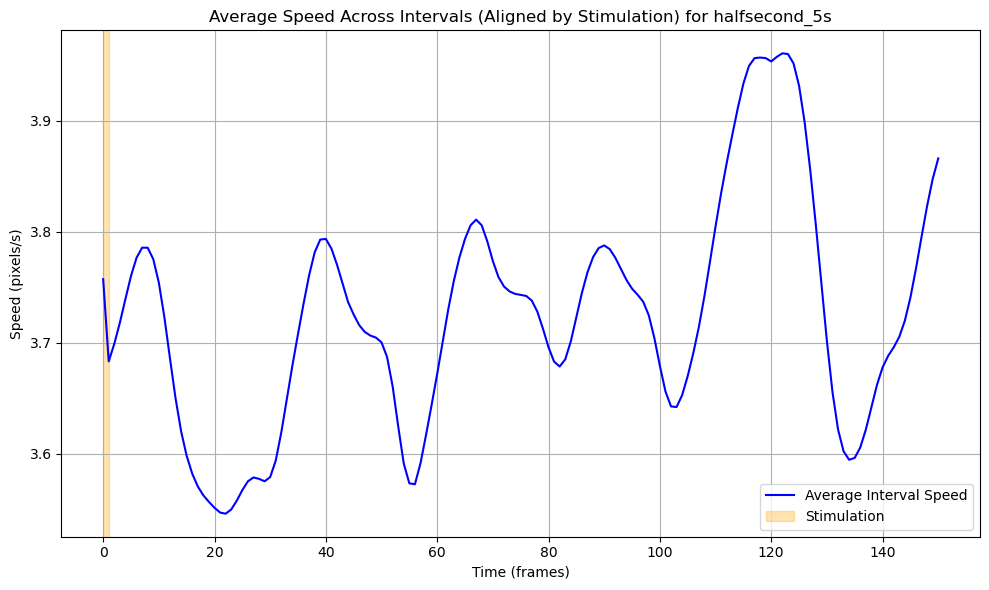

In [30]:
base_folder = '/Users/eneko/Desktop/Louis Lab/data collection/260514/halfsecond_5s'  # Replace with your folder path
plot_average_intervals_with_stimulation(base_folder, stimulation_column="Stim Ch1", stimvalue=80.0, smoothing_factor=2)
